<a href="https://colab.research.google.com/github/samritha07/Deep-Learning/blob/main/EX6_SAMRITHA_S_24BAD103.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

import re
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available     :", len(tf.config.list_physical_devices("GPU")) > 0)


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
TensorFlow version: 2.21.0
GPU available     : False


In [2]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

# 1. Load the IMDB Movie Reviews dataset (full vocabulary, so the text can be rebuilt)
(train_ids, y_train_full), (test_ids, y_test) = imdb.load_data()

print("Training reviews:", len(train_ids))
print("Testing reviews :", len(test_ids))
print("Label values    :", np.unique(y_train_full), "(0 = Negative, 1 = Positive)")

# Rebuild the original text of every review from the integer encoding
word_index = imdb.get_word_index()
id_to_word = {idx + 3: word for word, idx in word_index.items()}   # Keras offsets indices by 3

def ids_to_text(seq):
    # ids 0,1,2 are special markers (pad / start / unknown) -> skipped
    return " ".join(id_to_word.get(i, "") for i in seq if i >= 3)

train_texts_raw = [ids_to_text(s) for s in train_ids]
test_texts_raw = [ids_to_text(s) for s in test_ids]

print("\nNumber of text reviews rebuilt:", len(train_texts_raw) + len(test_texts_raw))


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000
Testing reviews : 25000
Label values    : [0 1] (0 = Negative, 1 = Positive)
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Number of text reviews rebuilt: 50000


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
Negative reviews (0): 12500
Positive reviews (1): 12500


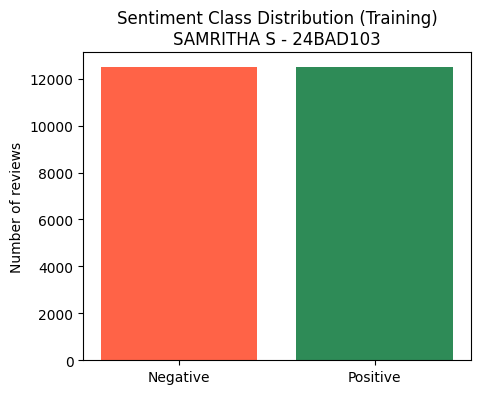


Average review length (words): 237.7
Median review length (words) : 177

Sample reviews and labels:

[1] Sentiment: Positive
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert redford's is an amazing actor and now the same being director norman's father came from the same scottish island as myself so i loved the  ...

[2] Sentiment: Negative
big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and ridiculous the acting is an abomination the script is completely ...

[3] Sentiment: Negative
this has to be one of the worst films of the 1990s when my friends i were watching this film being the target audience it was aimed at we just sat watched the first half an hour with our jaws touching the floor at 

In [3]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

# 2. Explore the dataset: class distribution and sample reviews
counts = pd.Series(y_train_full).value_counts().sort_index()
print("Negative reviews (0):", counts[0])
print("Positive reviews (1):", counts[1])

plt.figure(figsize=(5, 4))
plt.bar(["Negative", "Positive"], counts.values, color=["tomato", "seagreen"])
plt.title("Sentiment Class Distribution (Training)\nSAMRITHA S - 24BAD103")
plt.ylabel("Number of reviews")
plt.show()

lengths = [len(t.split()) for t in train_texts_raw]
print("\nAverage review length (words):", round(np.mean(lengths), 1))
print("Median review length (words) :", int(np.median(lengths)))

print("\nSample reviews and labels:")
for i in range(3):
    label = "Positive" if y_train_full[i] == 1 else "Negative"
    print(f"\n[{i+1}] Sentiment: {label}")
    print(train_texts_raw[i][:300], "...")


In [4]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

# 3. Text preprocessing: lowercase + remove unnecessary characters/symbols
def clean_text(text):
    text = text.lower()                          # lowercase
    text = re.sub(r"<[^>]+>", " ", text)         # remove any HTML tags
    text = re.sub(r"[^a-z' ]", " ", text)        # keep only letters, apostrophes and spaces
    text = re.sub(r"\s+", " ", text).strip()     # collapse extra spaces
    return text

# 4. Tokenization: split each review into words
def tokenize(text):
    return clean_text(text).split()

sample = "This movie was GREAT!!! <br />Loved it :) 10/10"
print("Original  :", sample)
print("Cleaned   :", clean_text(sample))
print("Tokenized :", tokenize(sample))

train_tokens = [tokenize(t) for t in train_texts_raw]
test_tokens = [tokenize(t) for t in test_texts_raw]
print("\nFirst review, first 15 tokens:", train_tokens[0][:15])


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
Original  : This movie was GREAT!!! <br />Loved it :) 10/10
Cleaned   : this movie was great loved it
Tokenized : ['this', 'movie', 'was', 'great', 'loved', 'it']

First review, first 15 tokens: ['this', 'film', 'was', 'just', 'brilliant', 'casting', 'location', 'scenery', 'story', 'direction', "everyone's", 'really', 'suited', 'the', 'part']


In [5]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

# 5. Build vocabulary and assign unique integer indices (built from TRAINING data only)
VOCAB_SIZE = 10000          # total vocabulary size (including PAD and OOV)
MAX_LEN = 200               # fixed review length after padding

word_counts = Counter(w for review in train_tokens for w in review)
most_common = [w for w, _ in word_counts.most_common(VOCAB_SIZE - 2)]

PAD_ID, OOV_ID = 0, 1
vocab = {"<PAD>": PAD_ID, "<OOV>": OOV_ID}
for i, w in enumerate(most_common, start=2):
    vocab[w] = i

print("Vocabulary size:", len(vocab))
print("Top 10 words and their indices:", [(w, vocab[w]) for w in most_common[:10]])

# 6. Convert text reviews into numerical sequences
def tokens_to_sequence(tokens):
    return [vocab.get(w, OOV_ID) for w in tokens]

train_seq = [tokens_to_sequence(t) for t in train_tokens]
test_seq = [tokens_to_sequence(t) for t in test_tokens]
print("\nFirst review as integers:", train_seq[0][:20])

# 7. Sequence padding so every input has equal length
X_full = pad_sequences(train_seq, maxlen=MAX_LEN, padding="pre", truncating="post")
X_test = pad_sequences(test_seq, maxlen=MAX_LEN, padding="pre", truncating="post")
y_full = np.array(y_train_full)
y_test = np.array(y_test)

print("Padded training data shape:", X_full.shape)
print("Padded testing data shape :", X_test.shape)


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
Vocabulary size: 10000
Top 10 words and their indices: [('the', 2), ('and', 3), ('a', 4), ('of', 5), ('to', 6), ('is', 7), ('br', 8), ('in', 9), ('it', 10), ('i', 11)]

First review as integers: [12, 20, 14, 41, 523, 961, 1602, 1372, 63, 454, 4396, 64, 3880, 2, 170, 34, 253, 3, 23, 98]
Padded training data shape: (25000, 200)
Padded testing data shape : (25000, 200)


In [6]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

# 8. Split into training and validation sets (test set is kept separate)
X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.2, random_state=SEED, stratify=y_full
)

print("Training samples  :", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Testing samples   :", X_test.shape[0])
print("Input shape per review:", X_train.shape[1:])


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
Training samples  : 20000
Validation samples: 5000
Testing samples   : 25000
Input shape per review: (200,)


In [7]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

EMBEDDING_DIM = 64

model = Sequential([
    Input(shape=(MAX_LEN,)),                                     # integer review of length 200
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),   # words -> dense vectors
    LSTM(64),                                                    # learns sequential dependencies
    Dropout(0.3),                                                # reduces over-fitting
    Dense(1, activation="sigmoid")                               # probability of positive sentiment
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("LSTM model created and compiled successfully.\n")
model.summary()


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
LSTM model created and compiled successfully.



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------


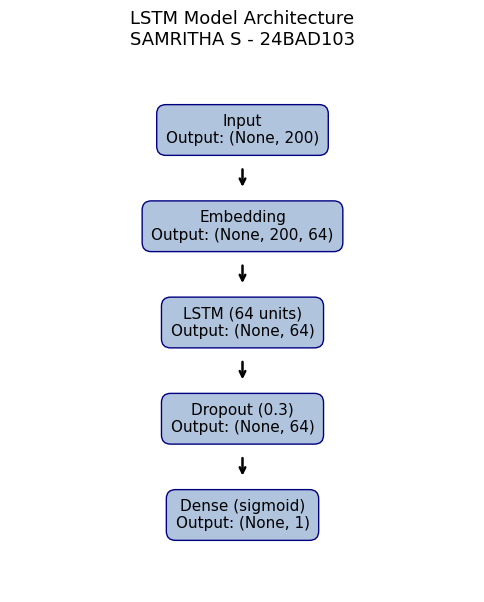

In [8]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

# Model architecture diagram (drawn with Matplotlib, so no extra software is needed)
layers_info = [
    ("Input", f"(None, {MAX_LEN})"),
    ("Embedding", f"(None, {MAX_LEN}, {EMBEDDING_DIM})"),
    ("LSTM (64 units)", "(None, 64)"),
    ("Dropout (0.3)", "(None, 64)"),
    ("Dense (sigmoid)", "(None, 1)"),
]

fig, ax = plt.subplots(figsize=(6, 7))
ax.axis("off")
n = len(layers_info)
for i, (name, shape) in enumerate(layers_info):
    y = n - i
    ax.text(0.5, y, f"{name}\nOutput: {shape}", ha="center", va="center", fontsize=11,
            bbox=dict(boxstyle="round,pad=0.6", fc="lightsteelblue", ec="navy"))
    if i < n - 1:
        ax.annotate("", xy=(0.5, y - 0.62), xytext=(0.5, y - 0.38),
                    arrowprops=dict(arrowstyle="->", lw=1.8))
ax.set_xlim(0, 1)
ax.set_ylim(0.2, n + 0.8)
ax.set_title("LSTM Model Architecture\nSAMRITHA S - 24BAD103", fontsize=13)
plt.show()


In [9]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

EPOCHS = 5
BATCH_SIZE = 128

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    verbose=1
)

print("\nModel training completed successfully.")


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 48s 290ms/step - accuracy: 0.7368 - loss: 0.5221 - val_accuracy: 0.8150 - val_loss: 0.4251
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 47s 298ms/step - accuracy: 0.8826 - loss: 0.2995 - val_accuracy: 0.8360 - val_loss: 0.4053
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 45s 289ms/step - accuracy: 0.9061 - loss: 0.2500 - val_accuracy: 0.8498 - val_loss: 0.3837
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 84s 303ms/step - accuracy: 0.9133 - loss: 0.2300 - val_accuracy: 0.8354 - val_loss: 0.4763
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 46s 295ms/step - accuracy: 0.9244 - loss: 0.2058 - val_accuracy: 0.8192 - val_loss: 0.4226

Model training completed successfully.


In [10]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

# Record training / validation accuracy and loss
results = pd.DataFrame({
    "Epoch": range(1, EPOCHS + 1),
    "Training Accuracy": history.history["accuracy"],
    "Validation Accuracy": history.history["val_accuracy"],
    "Training Loss": history.history["loss"],
    "Validation Loss": history.history["val_loss"],
})
print(results.round(4).to_string(index=False))


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
 Epoch  Training Accuracy  Validation Accuracy  Training Loss  Validation Loss
     1             0.7368               0.8150         0.5221           0.4251
     2             0.8826               0.8360         0.2995           0.4053
     3             0.9061               0.8498         0.2500           0.3837
     4             0.9133               0.8354         0.2300           0.4763
     5             0.9244               0.8192         0.2058           0.4226


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------


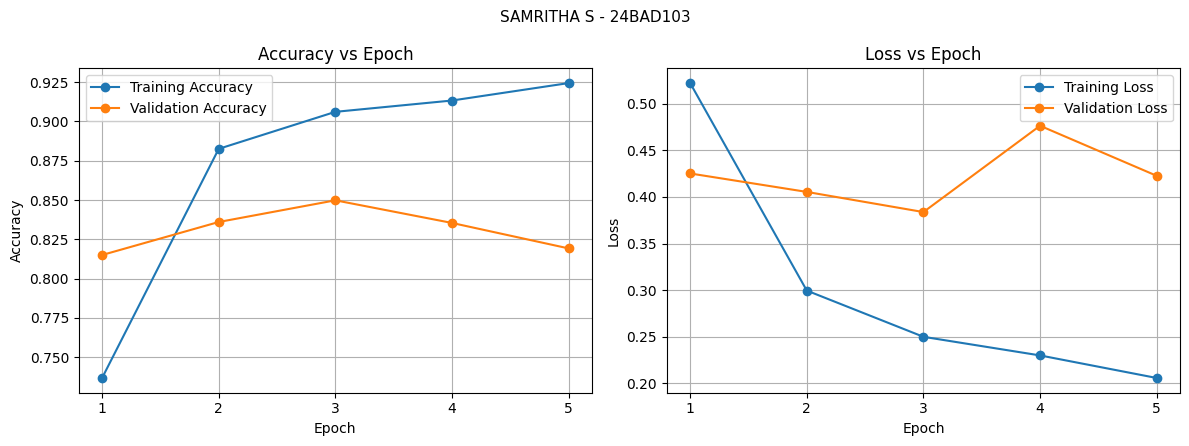

In [11]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

# Accuracy vs Epoch  and  Loss vs Epoch
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["loss"], marker="o", label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True)

plt.suptitle("SAMRITHA S - 24BAD103", fontsize=11)
plt.tight_layout()
plt.show()


In [12]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

# Evaluate on the test dataset
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print("\nTest Loss    :", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4), f"({test_accuracy * 100:.2f}%)")

# Accuracy, Precision, Recall, F1-score
y_prob = model.predict(X_test, batch_size=256, verbose=0).flatten()
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification Metrics")
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-Score :", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], zero_division=0))


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
782/782 ━━━━━━━━━━━━━━━━━━━━ 19s 24ms/step - accuracy: 0.8186 - loss: 0.4241

Test Loss    : 0.4241
Test Accuracy: 0.8186 (81.86%)

Classification Metrics
Accuracy : 0.8186
Precision: 0.8141
Recall   : 0.8259
F1-Score : 0.82

Detailed Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.81      0.82     12500
    Positive       0.81      0.83      0.82     12500

    accuracy                           0.82     25000
   macro avg       0.82      0.82      0.82     25000
weighted avg       0.82      0.82      0.82     25000



Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
Confusion Matrix:
[[10142  2358]
 [ 2176 10324]]


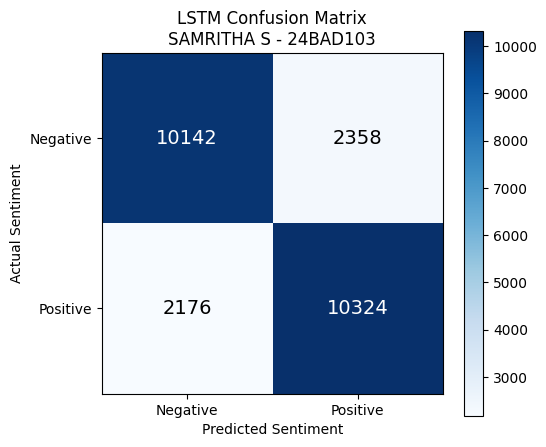

In [13]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Negative", "Positive"])
ax.set_yticklabels(["Negative", "Positive"])
ax.set_xlabel("Predicted Sentiment")
ax.set_ylabel("Actual Sentiment")
ax.set_title("LSTM Confusion Matrix\nSAMRITHA S - 24BAD103")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im)
plt.show()


In [14]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

def preprocess_review(review):
    """Clean -> tokenize -> map with training vocabulary -> pad (same steps as training)."""
    tokens = tokenize(review)
    seq = tokens_to_sequence(tokens)
    return pad_sequences([seq], maxlen=MAX_LEN, padding="pre", truncating="post")

def predict_sentiment(review):
    prob = float(model.predict(preprocess_review(review), verbose=0)[0][0])
    label = "Positive" if prob >= 0.5 else "Negative"
    return label, prob

new_reviews = [
    "This movie was amazing and the acting was excellent",
    "The film was boring and a complete waste of time",
    "I loved the story and the performances were wonderful",
    "The movie was terrible and I hated every minute",
    "The film was enjoyable and entertaining",
    "The story was weak and the acting was disappointing",
]
expected = ["Positive", "Negative", "Positive", "Negative", "Positive", "Negative"]

rows = []
for review, exp in zip(new_reviews, expected):
    pred, prob = predict_sentiment(review)
    rows.append({
        "Review": review,
        "Expected": exp,
        "Predicted": pred,
        "Positive Probability": round(prob, 4),
        "Correct": "Yes" if pred == exp else "No",
    })

comparison_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)
print("LSTM SENTIMENT PREDICTION RESULTS\n")
print(comparison_df.to_string(index=False))

correct = (comparison_df["Correct"] == "Yes").sum()
print(f"\nCorrect predictions: {correct} / {len(comparison_df)}  ({correct / len(comparison_df) * 100:.1f}%)")


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------
LSTM SENTIMENT PREDICTION RESULTS

                                               Review Expected Predicted  Positive Probability Correct
  This movie was amazing and the acting was excellent Positive  Positive                0.9578     Yes
     The film was boring and a complete waste of time Negative  Negative                0.0246     Yes
I loved the story and the performances were wonderful Positive  Positive                0.9826     Yes
      The movie was terrible and I hated every minute Negative  Negative                0.1216     Yes
              The film was enjoyable and entertaining Positive  Positive                0.9440     Yes
  The story was weak and the acting was disappointing Negative  Negative                0.0193     Yes

Correct predictions: 6 / 6  (100.0%)


Name: SAMRITHA S | Roll No: 24BAD103
------------------------------------------------------------


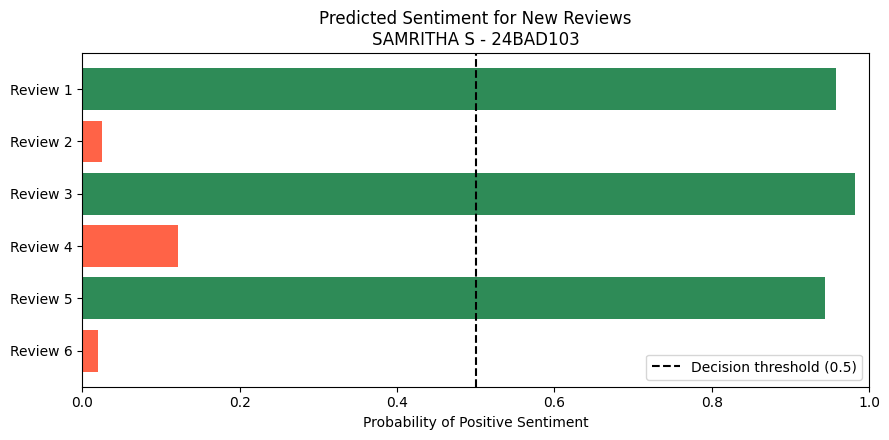

In [15]:
# Name: SAMRITHA S | Roll No: 24BAD103
print("Name: SAMRITHA S | Roll No: 24BAD103")
print("-" * 60)

# Visual comparison of predicted probabilities
plt.figure(figsize=(9, 4.5))
colors = ["seagreen" if p == "Positive" else "tomato" for p in comparison_df["Predicted"]]
plt.barh([f"Review {i+1}" for i in range(len(comparison_df))],
         comparison_df["Positive Probability"], color=colors)
plt.axvline(0.5, color="black", linestyle="--", label="Decision threshold (0.5)")
plt.xlabel("Probability of Positive Sentiment")
plt.title("Predicted Sentiment for New Reviews\nSAMRITHA S - 24BAD103")
plt.xlim(0, 1)
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
